# Laboratorio Evaluado: WBCD y Evaluación Multimodelo

**Reto Autónomo: Clínica Oncológica**

Eres el Consultor IA de un hospital. El dataset WBCD (*Wisconsin Breast Cancer Diagnostic*) contiene radios, perímetros, texturas y otras medidas de núcleos celulares. Debes entrenar **k-NN** y **Árboles de Decisión**, y validar **qué pasa si no escalas los datos**.

**Contenido del laboratorio**
1. Carga y exploración de datos
2. Preprocesamiento y split 80/20
3. Escalamiento (solo para k-NN)
4. Modelado y matrices de confusión
5. *Extra:* ¿Qué pasa si NO escalamos? (experimento)
6. *Extra:* Métricas clínicas (Precision, Recall, F1) y curvas ROC
7. *Extra:* Validación cruzada, búsqueda del mejor *k* y *max_depth*
8. *Extra:* Interpretabilidad del árbol
9. *Extra:* Ajuste del umbral para minimizar Falsos Negativos
10. Evaluación teórica / decisión de negocios

## 1. Carga de Datos y Exploración

In [1]:
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score, GridSearchCV
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import (confusion_matrix, classification_report, accuracy_score,
                             precision_score, recall_score, f1_score, roc_curve, roc_auc_score,
                             ConfusionMatrixDisplay)

sns.set_theme(style="whitegrid")
RANDOM_STATE = 42

# Nombres de columnas oficiales del WDBC (30 medidas = 10 características x {media, error estándar, peor valor})
base = ["radio", "textura", "perimetro", "area", "suavidad", "compacidad",
        "concavidad", "puntos_concavos", "simetria", "dim_fractal"]
columnas = ["id", "diagnosis"] + [f"{b}_{s}" for s in ["media", "error", "peor"] for b in base]

URL = "https://archive.ics.uci.edu/ml/machine-learning-databases/breast-cancer-wisconsin/wdbc.data"

try:
    # Intento 1: descargar directamente desde UCI
    df_wbcd = pd.read_csv(URL, header=None, names=columnas)
    print("✅ Dataset cargado desde UCI.")
except Exception as e:
    # Intento 2 (respaldo sin internet): el mismo WDBC viene incluido en scikit-learn
    from sklearn.datasets import load_breast_cancer
    data = load_breast_cancer()
    df_wbcd = pd.DataFrame(data.data, columns=columnas[2:])
    # En sklearn: 0 = maligno, 1 = benigno. En UCI: M / B. Lo reconstruimos como UCI.
    df_wbcd.insert(0, "diagnosis", np.where(data.target == 0, "M", "B"))
    df_wbcd.insert(0, "id", np.arange(len(df_wbcd)))
    print("⚠️ Sin acceso a UCI. Cargado el mismo WDBC desde scikit-learn (idéntico: 569 filas, 30 variables).")

print("Dimensiones:", df_wbcd.shape)
display(df_wbcd.head())

⚠️ Sin acceso a UCI. Cargado el mismo WDBC desde scikit-learn (idéntico: 569 filas, 30 variables).
Dimensiones: (569, 32)


,id,diagnosis,radio_media,textura_media,perimetro_media,area_media,suavidad_media,compacidad_media,concavidad_media,puntos_concavos_media,...,radio_peor,textura_peor,perimetro_peor,area_peor,suavidad_peor,compacidad_peor,concavidad_peor,puntos_concavos_peor,simetria_peor,dim_fractal_peor
0,0,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,1,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,2,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,3,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,4,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


Valores nulos totales: 0
Filas duplicadas (por id): 0

Distribución del diagnóstico:
diagnosis
B    357
M    212
Name: count, dtype: int64
diagnosis
B    62.7 %
M    37.3 %
Name: proportion, dtype: str


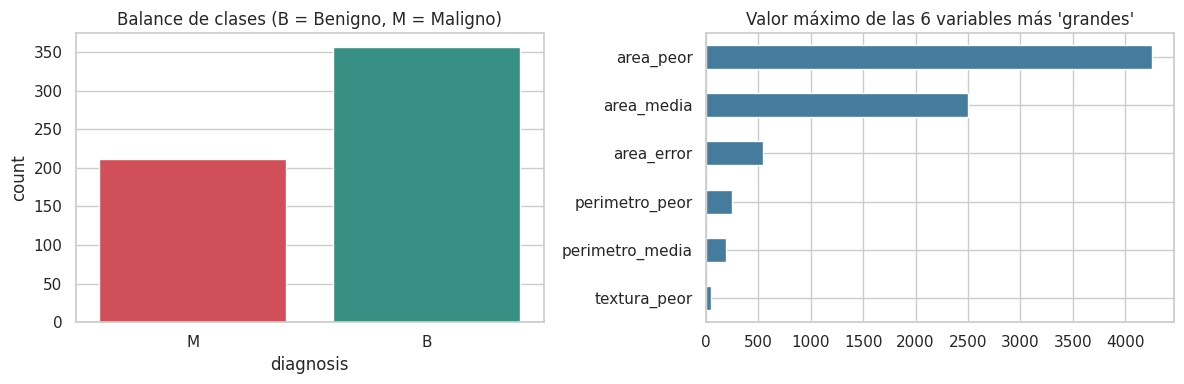

In [2]:
print("Valores nulos totales:", df_wbcd.isnull().sum().sum())
print("Filas duplicadas (por id):", df_wbcd["id"].duplicated().sum())
print("\nDistribución del diagnóstico:")
print(df_wbcd["diagnosis"].value_counts())
print((df_wbcd["diagnosis"].value_counts(normalize=True) * 100).round(1).astype(str) + " %")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.countplot(x="diagnosis", data=df_wbcd, palette={"B": "#2a9d8f", "M": "#e63946"}, ax=axes[0])
axes[0].set_title("Balance de clases (B = Benigno, M = Maligno)")

# Magnitud de las variables: el problema de la escala
rangos = df_wbcd.drop(columns=["id", "diagnosis"]).max().sort_values(ascending=False).head(6)
rangos.plot(kind="barh", ax=axes[1], color="#457b9d")
axes[1].invert_yaxis()
axes[1].set_title("Valor máximo de las 6 variables más 'grandes'")
plt.tight_layout(); plt.show()

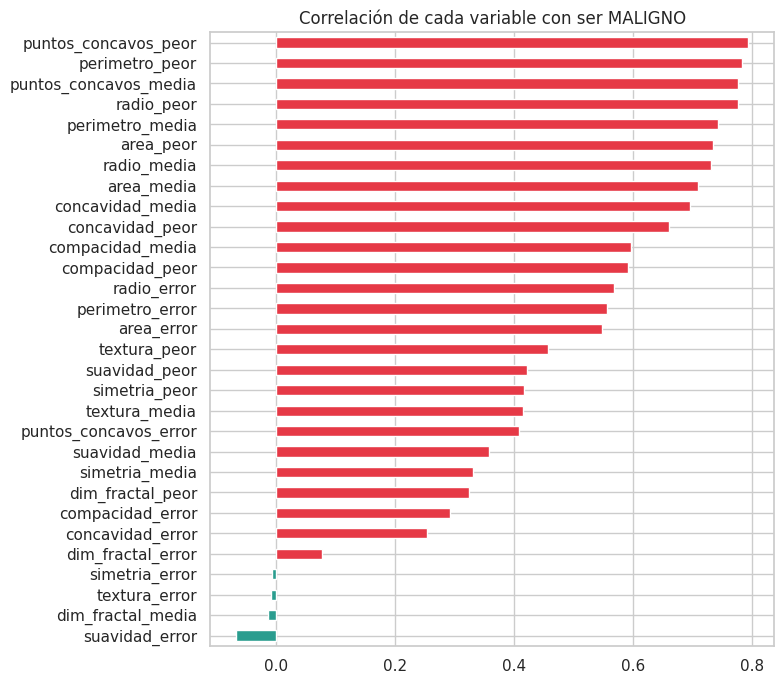

Top 5 variables asociadas a malignidad:
puntos_concavos_peor     0.794
perimetro_peor           0.783
puntos_concavos_media    0.777
radio_peor               0.776
perimetro_media          0.743
Name: diagnosis, dtype: float64


In [3]:
# Variables más relacionadas con el diagnóstico maligno
tmp = df_wbcd.drop(columns="id").copy()
tmp["diagnosis"] = (tmp["diagnosis"] == "M").astype(int)
corr_target = tmp.corr()["diagnosis"].drop("diagnosis").sort_values(ascending=False)

plt.figure(figsize=(8, 7))
corr_target.plot(kind="barh", color=np.where(corr_target > 0, "#e63946", "#2a9d8f"))
plt.gca().invert_yaxis()
plt.title("Correlación de cada variable con ser MALIGNO")
plt.tight_layout(); plt.show()

print("Top 5 variables asociadas a malignidad:")
print(corr_target.head(5).round(3))

## 2. Preprocesamiento

In [4]:
# 1) Convertir diagnosis (M/B) a binario: M (Maligno) = 1 (clase positiva), B (Benigno) = 0
df_wbcd["target"] = df_wbcd["diagnosis"].map({"M": 1, "B": 0})

# 2) Separar X (features) e y (target). Se elimina 'id' porque no aporta información clínica.
X = df_wbcd.drop(columns=["id", "diagnosis", "target"])
y = df_wbcd["target"]

# 3) Split 80% train / 20% test. stratify=y mantiene la misma proporción M/B en ambos conjuntos.
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=RANDOM_STATE, stratify=y
)

print(f"Train: {X_train.shape[0]} pacientes | Test: {X_test.shape[0]} pacientes | Variables: {X.shape[1]}")
print(f"% malignos en train: {y_train.mean()*100:.1f}% | en test: {y_test.mean()*100:.1f}%")

Train: 455 pacientes | Test: 114 pacientes | Variables: 30
% malignos en train: 37.4% | en test: 36.8%


## 3. Escalamiento (Solo para k-NN)

In [5]:
# .fit_transform() SOLO en train (aprende media y desviación) y .transform() en test (aplica lo aprendido).
# Esto evita "data leakage": el test debe ser como pacientes que el modelo nunca ha visto.
scaler = StandardScaler()
X_train_esc = scaler.fit_transform(X_train)
X_test_esc = scaler.transform(X_test)

comp = pd.DataFrame({
    "Media (antes)": X_train[["area_media", "radio_media", "suavidad_media"]].mean(),
    "Media (después)": pd.DataFrame(X_train_esc, columns=X.columns)[["area_media", "radio_media", "suavidad_media"]].mean(),
    "Desv. (antes)": X_train[["area_media", "radio_media", "suavidad_media"]].std(),
    "Desv. (después)": pd.DataFrame(X_train_esc, columns=X.columns)[["area_media", "radio_media", "suavidad_media"]].std(),
}).round(3)
display(comp)

,Media (antes),Media (después),Desv. (antes),Desv. (después)
area_media,659.578,-0.0,360.419,1.001
radio_media,14.166,-0.0,3.579,1.001
suavidad_media,0.096,0.0,0.014,1.001


## 4. Modelado y Matrices de Confusión

In [6]:
# Modelo 1: k-NN (con datos escalados)
knn = KNeighborsClassifier(n_neighbors=5)
knn.fit(X_train_esc, y_train)
pred_knn = knn.predict(X_test_esc)

# Modelo 2: Árbol de Decisión (datos originales, sin escalar)
arbol = DecisionTreeClassifier(max_depth=4, random_state=RANDOM_STATE)
arbol.fit(X_train, y_train)
pred_arbol = arbol.predict(X_test)

# Matrices de confusión (texto)
for nombre, pred in [("k-NN (k=5, escalado)", pred_knn), ("Árbol de Decisión (max_depth=4)", pred_arbol)]:
    cm = confusion_matrix(y_test, pred)
    tn, fp, fn, tp = cm.ravel()
    print(f"=== {nombre} ===")
    print(cm)
    print(f"Verdaderos Negativos={tn} | Falsos Positivos={fp} | Falsos Negativos={fn} | Verdaderos Positivos={tp}")
    print(f"Accuracy = {accuracy_score(y_test, pred)*100:.2f}%\n")

=== k-NN (k=5, escalado) ===
[[71  1]
 [ 4 38]]
Verdaderos Negativos=71 | Falsos Positivos=1 | Falsos Negativos=4 | Verdaderos Positivos=38
Accuracy = 95.61%

=== Árbol de Decisión (max_depth=4) ===
[[70  2]
 [ 8 34]]
Verdaderos Negativos=70 | Falsos Positivos=2 | Falsos Negativos=8 | Verdaderos Positivos=34
Accuracy = 91.23%



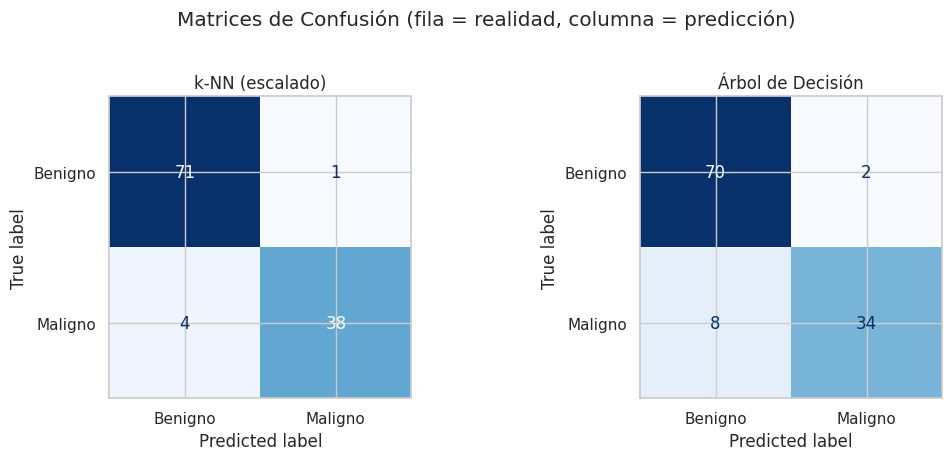

In [7]:
# Matrices de confusión (visual)
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))
for ax, (nombre, pred) in zip(axes, [("k-NN (escalado)", pred_knn), ("Árbol de Decisión", pred_arbol)]):
    ConfusionMatrixDisplay.from_predictions(
        y_test, pred, display_labels=["Benigno", "Maligno"], cmap="Blues", ax=ax, colorbar=False)
    ax.set_title(nombre)
plt.suptitle("Matrices de Confusión (fila = realidad, columna = predicción)", y=1.02)
plt.tight_layout(); plt.show()

## 5. Extra: ¿Qué pasa si NO escalamos?

Aquí validamos la hipótesis del reto. Entrenamos **k-NN** y **Árbol** de las dos formas (con y sin escalar) y comparamos.

,Accuracy,Recall (Malignos detectados),Falsos Negativos,Falsos Positivos
Modelo,,,,
k-NN SIN escalar,91.23%,78.57%,9,1
k-NN CON escalar,95.61%,90.48%,4,1
Árbol SIN escalar,91.23%,80.95%,8,2
Árbol CON escalar,91.23%,80.95%,8,2


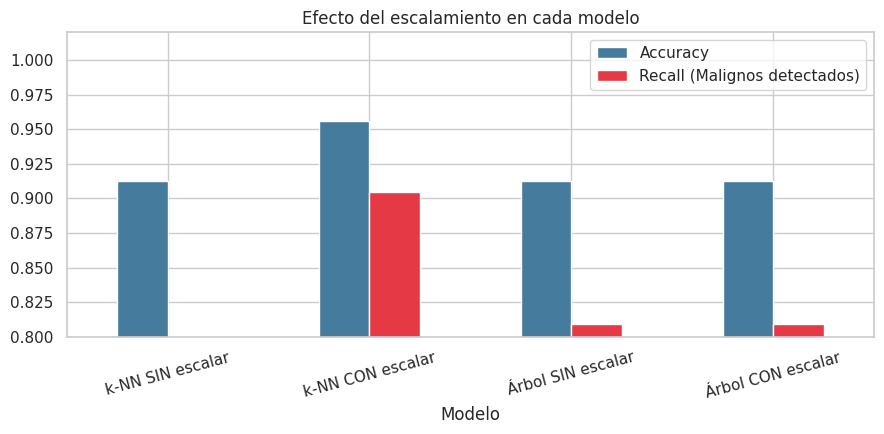

In [8]:
knn_sin = KNeighborsClassifier(n_neighbors=5).fit(X_train, y_train)          # SIN escalar
arbol_con = DecisionTreeClassifier(max_depth=4, random_state=RANDOM_STATE).fit(X_train_esc, y_train)  # CON escalar

def resumen(nombre, modelo, Xte):
    p = modelo.predict(Xte)
    tn, fp, fn, tp = confusion_matrix(y_test, p).ravel()
    return {"Modelo": nombre,
            "Accuracy": accuracy_score(y_test, p),
            "Recall (Malignos detectados)": recall_score(y_test, p),
            "Falsos Negativos": fn, "Falsos Positivos": fp}

tabla_escala = pd.DataFrame([
    resumen("k-NN SIN escalar", knn_sin, X_test),
    resumen("k-NN CON escalar", knn, X_test_esc),
    resumen("Árbol SIN escalar", arbol, X_test),
    resumen("Árbol CON escalar", arbol_con, X_test_esc),
]).set_index("Modelo")
display(tabla_escala.style.format({"Accuracy": "{:.2%}", "Recall (Malignos detectados)": "{:.2%}"})
        .background_gradient(cmap="RdYlGn", subset=["Accuracy", "Recall (Malignos detectados)"]))

ax = tabla_escala[["Accuracy", "Recall (Malignos detectados)"]].plot(kind="bar", figsize=(9, 4.5), color=["#457b9d", "#e63946"])
ax.set_ylim(0.8, 1.02); ax.set_title("Efecto del escalamiento en cada modelo"); plt.xticks(rotation=15)
plt.tight_layout(); plt.show()

In [9]:
# ¿Por qué falla k-NN sin escalar? Miremos qué variable domina la distancia.
rango = (X_train.max() - X_train.min()).sort_values(ascending=False)
print("Rango (máx - mín) de las 5 variables que más pesan en la distancia euclidiana:")
print(rango.head(5).round(2))
print("\nRango de las 5 que menos pesan:")
print(rango.tail(5).round(4))
print(f"\n'area_peor' pesa ~{rango.iloc[0]/rango.iloc[-1]:,.0f} veces más que la variable más pequeña.")

Rango (máx - mín) de las 5 variables que más pesan en la distancia euclidiana:
area_peor          4068.80
area_media         2357.50
area_error          535.40
perimetro_peor      200.79
perimetro_media     144.71
dtype: float64

Rango de las 5 que menos pesan:
simetria_error           0.0711
puntos_concavos_error    0.0528
dim_fractal_media        0.0472
suavidad_error           0.0294
dim_fractal_error        0.0289
dtype: float64

'area_peor' pesa ~140,569 veces más que la variable más pequeña.


## 6. Extra: Métricas clínicas y curvas ROC

In [10]:
for nombre, pred in [("k-NN (escalado)", pred_knn), ("Árbol de Decisión", pred_arbol)]:
    print(f"===== {nombre} =====")
    print(classification_report(y_test, pred, target_names=["Benigno", "Maligno"], digits=3))

===== k-NN (escalado) =====
              precision    recall  f1-score   support

     Benigno      0.947     0.986     0.966        72
     Maligno      0.974     0.905     0.938        42

    accuracy                          0.956       114
   macro avg      0.961     0.945     0.952       114
weighted avg      0.957     0.956     0.956       114

===== Árbol de Decisión =====
              precision    recall  f1-score   support

     Benigno      0.897     0.972     0.933        72
     Maligno      0.944     0.810     0.872        42

    accuracy                          0.912       114
   macro avg      0.921     0.891     0.903       114
weighted avg      0.915     0.912     0.911       114



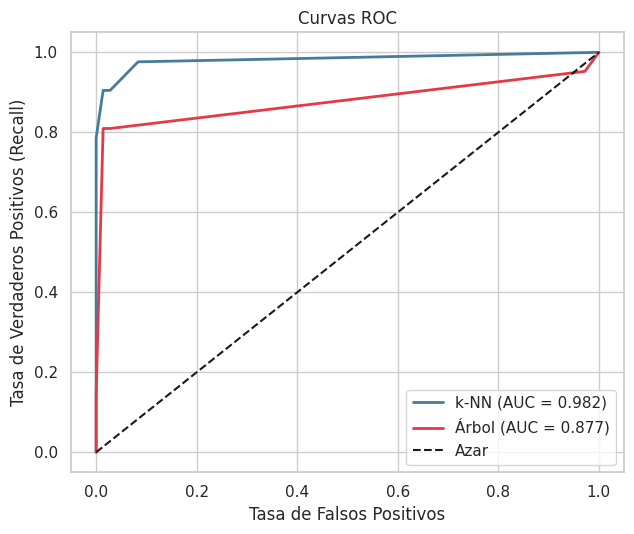

In [11]:
prob_knn = knn.predict_proba(X_test_esc)[:, 1]
prob_arbol = arbol.predict_proba(X_test)[:, 1]

plt.figure(figsize=(6.5, 5.5))
for nombre, prob, color in [("k-NN", prob_knn, "#457b9d"), ("Árbol", prob_arbol, "#e63946")]:
    fpr, tpr, _ = roc_curve(y_test, prob)
    plt.plot(fpr, tpr, label=f"{nombre} (AUC = {roc_auc_score(y_test, prob):.3f})", color=color, lw=2)
plt.plot([0, 1], [0, 1], "k--", label="Azar")
plt.xlabel("Tasa de Falsos Positivos"); plt.ylabel("Tasa de Verdaderos Positivos (Recall)")
plt.title("Curvas ROC"); plt.legend(loc="lower right"); plt.tight_layout(); plt.show()

## 7. Extra: Validación cruzada y ajuste de hiperparámetros

In [12]:
# Un solo split puede ser suerte. Con 5-fold CV estratificado obtenemos una estimación más confiable.
# Usamos Pipeline para que el escalador se ajuste DENTRO de cada fold (sin fuga de datos).
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

modelos_cv = {
    "k-NN sin escalar": KNeighborsClassifier(n_neighbors=5),
    "k-NN escalado": Pipeline([("sc", StandardScaler()), ("knn", KNeighborsClassifier(n_neighbors=5))]),
    "Árbol (depth=4)": DecisionTreeClassifier(max_depth=4, random_state=RANDOM_STATE),
}
filas = []
for nombre, m in modelos_cv.items():
    acc = cross_val_score(m, X, y, cv=cv, scoring="accuracy")
    rec = cross_val_score(m, X, y, cv=cv, scoring="recall")
    filas.append({"Modelo": nombre, "Accuracy medio": acc.mean(), "± Acc": acc.std(),
                  "Recall medio": rec.mean(), "± Recall": rec.std()})
cv_df = pd.DataFrame(filas).set_index("Modelo")
display(cv_df.style.format("{:.3f}").background_gradient(cmap="RdYlGn", subset=["Accuracy medio", "Recall medio"]))

,Accuracy medio,± Acc,Recall medio,± Recall
Modelo,,,,
k-NN sin escalar,0.935,0.020,0.892,0.062
k-NN escalado,0.963,0.018,0.925,0.046
Árbol (depth=4),0.923,0.030,0.873,0.072


Mejor k para k-NN : {'knn__n_neighbors': 3} -> Recall CV = 0.935
Mejor profundidad : {'max_depth': 8} -> Recall CV = 0.894


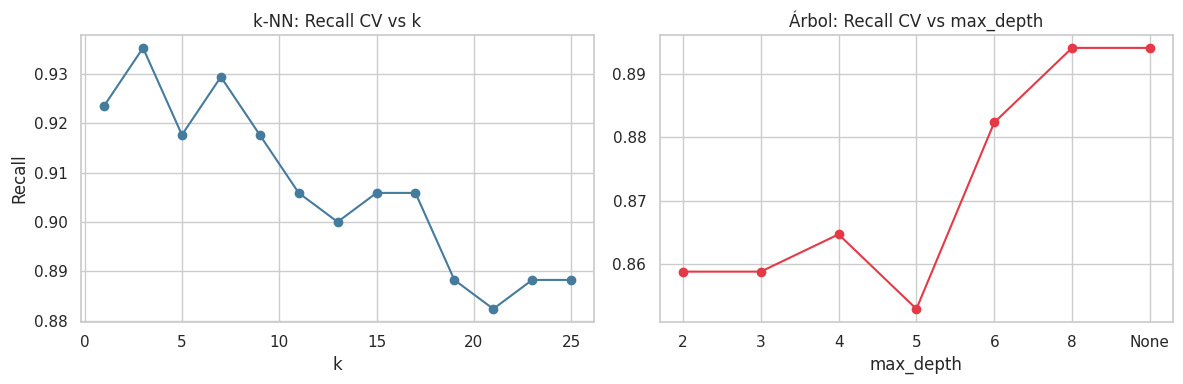

In [13]:
# Búsqueda del mejor k (con escalado dentro del pipeline) y de la mejor profundidad del árbol, optimizando RECALL
pipe_knn = Pipeline([("sc", StandardScaler()), ("knn", KNeighborsClassifier())])
gs_knn = GridSearchCV(pipe_knn, {"knn__n_neighbors": list(range(1, 26, 2))}, cv=cv, scoring="recall").fit(X_train, y_train)
gs_arbol = GridSearchCV(DecisionTreeClassifier(random_state=RANDOM_STATE),
                        {"max_depth": [2, 3, 4, 5, 6, 8, None]}, cv=cv, scoring="recall").fit(X_train, y_train)

print("Mejor k para k-NN :", gs_knn.best_params_, f"-> Recall CV = {gs_knn.best_score_:.3f}")
print("Mejor profundidad :", gs_arbol.best_params_, f"-> Recall CV = {gs_arbol.best_score_:.3f}")

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
ks = [p["knn__n_neighbors"] for p in gs_knn.cv_results_["params"]]
axes[0].plot(ks, gs_knn.cv_results_["mean_test_score"], "o-", color="#457b9d")
axes[0].set_title("k-NN: Recall CV vs k"); axes[0].set_xlabel("k"); axes[0].set_ylabel("Recall")
dp = [str(p["max_depth"]) for p in gs_arbol.cv_results_["params"]]
axes[1].plot(dp, gs_arbol.cv_results_["mean_test_score"], "o-", color="#e63946")
axes[1].set_title("Árbol: Recall CV vs max_depth"); axes[1].set_xlabel("max_depth")
plt.tight_layout(); plt.show()

In [14]:
# Evaluación final de los modelos optimizados en el TEST (que nunca se usó para ajustar)
knn_opt, arbol_opt = gs_knn.best_estimator_, gs_arbol.best_estimator_
final = pd.DataFrame([
    resumen("k-NN base (k=5)", knn, X_test_esc),
    {**{"Modelo": "k-NN optimizado"}, **{k: v for k, v in resumen("", knn_opt, X_test).items() if k != "Modelo"}},
    resumen("Árbol base (depth=4)", arbol, X_test),
    {**{"Modelo": "Árbol optimizado"}, **{k: v for k, v in resumen("", arbol_opt, X_test).items() if k != "Modelo"}},
]).set_index("Modelo")
display(final.style.format({"Accuracy": "{:.2%}", "Recall (Malignos detectados)": "{:.2%}"}))
print("Nota: el test tiene solo 114 pacientes (42 malignos): 1 caso de diferencia mueve el Recall ~2.4 puntos.")
print("Optimizar en CV no garantiza mejorar en un test pequeño; por eso la validación cruzada (sección 7) es más confiable.")

,Accuracy,Recall (Malignos detectados),Falsos Negativos,Falsos Positivos
Modelo,,,,
k-NN base (k=5),95.61%,90.48%,4,1
k-NN optimizado,93.86%,85.71%,6,1
Árbol base (depth=4),91.23%,80.95%,8,2
Árbol optimizado,92.98%,90.48%,4,4


Nota: el test tiene solo 114 pacientes (42 malignos): 1 caso de diferencia mueve el Recall ~2.4 puntos.
Optimizar en CV no garantiza mejorar en un test pequeño; por eso la validación cruzada (sección 7) es más confiable.


## 8. Extra: Interpretabilidad del Árbol (¿en qué se fija el modelo?)

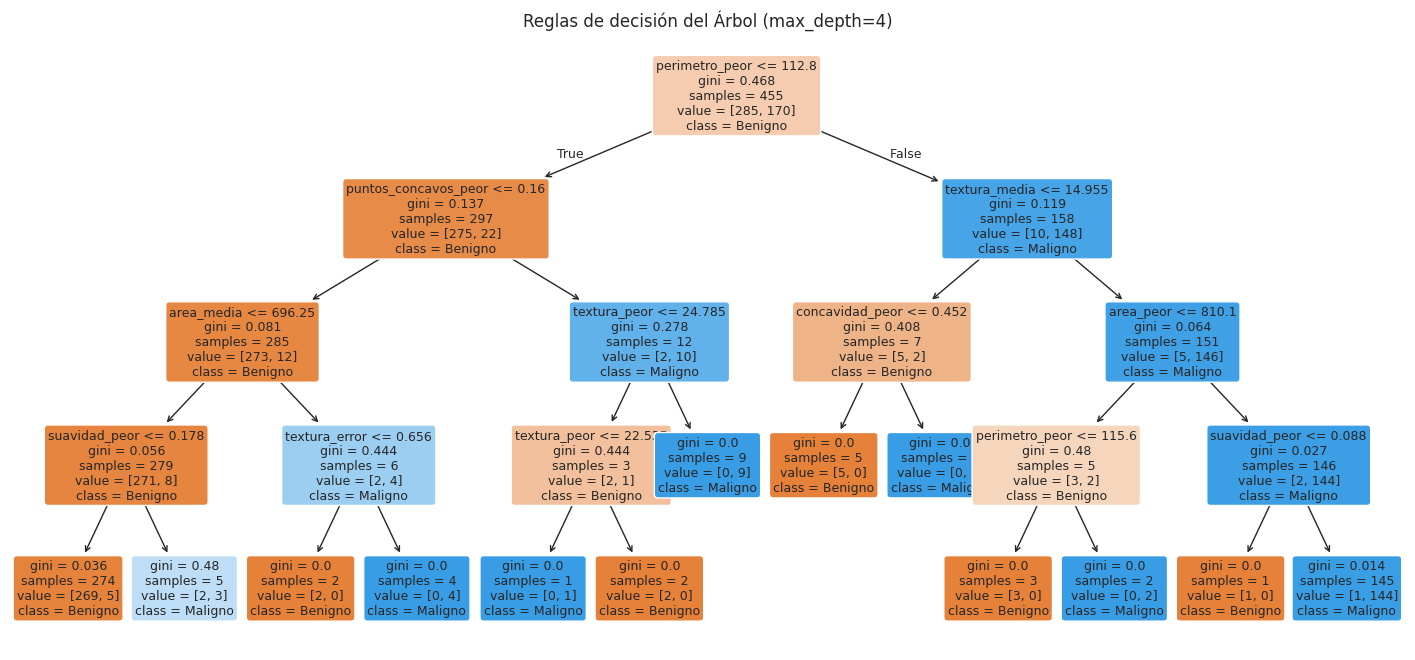

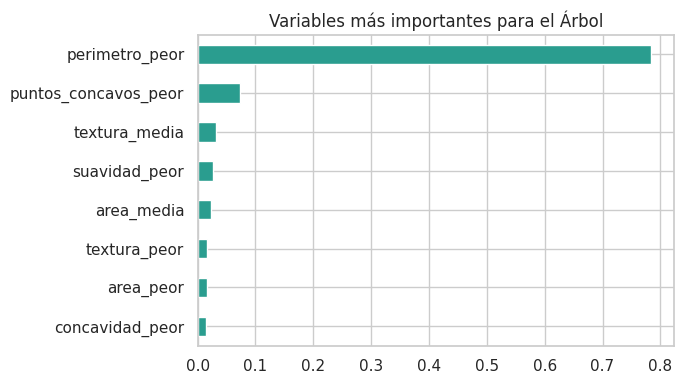

In [15]:
plt.figure(figsize=(18, 8))
plot_tree(arbol, feature_names=X.columns, class_names=["Benigno", "Maligno"], filled=True, rounded=True, fontsize=9)
plt.title("Reglas de decisión del Árbol (max_depth=4)"); plt.show()

imp = pd.Series(arbol.feature_importances_, index=X.columns).sort_values(ascending=False).head(8)
plt.figure(figsize=(7, 4)); imp[::-1].plot(kind="barh", color="#2a9d8f")
plt.title("Variables más importantes para el Árbol"); plt.tight_layout(); plt.show()

## 9. Extra: Ajuste del umbral para reducir Falsos Negativos

Por defecto un modelo declara *maligno* si la probabilidad supera 0.5. En medicina podemos **bajar el umbral** para no dejar escapar casos, aceptando a cambio más Falsos Positivos (que se resuelven con una biopsia de confirmación).

In [16]:
umbrales = [0.5, 0.4, 0.3, 0.2, 0.1]
filas = []
for u in umbrales:
    p = (prob_knn >= u).astype(int)
    tn, fp, fn, tp = confusion_matrix(y_test, p).ravel()
    filas.append({"Umbral": u, "Falsos Negativos": fn, "Falsos Positivos": fp,
                  "Recall": recall_score(y_test, p), "Precision": precision_score(y_test, p, zero_division=0)})
umb = pd.DataFrame(filas).set_index("Umbral")
display(umb.style.format({"Recall": "{:.2%}", "Precision": "{:.2%}"}).background_gradient(cmap="RdYlGn", subset=["Recall"]))
print("Nota: con k=5 las probabilidades de k-NN solo toman valores 0, .2, .4, .6, .8, 1, por eso los umbrales cambian a saltos.")

,Falsos Negativos,Falsos Positivos,Recall,Precision
Umbral,,,,
0.500000,4,1,90.48%,97.44%
0.400000,4,2,90.48%,95.00%
0.300000,4,2,90.48%,95.00%
0.200000,1,6,97.62%,87.23%
0.100000,1,6,97.62%,87.23%


Nota: con k=5 las probabilidades de k-NN solo toman valores 0, .2, .4, .6, .8, 1, por eso los umbrales cambian a saltos.


## Evaluación Teórica / Decisión de Negocios

**1. En este escenario médico, ¿qué implica un Error Tipo II (Falso Negativo) y por qué cuesta vidas?**

Definimos *Maligno = 1* como la clase positiva. Un **Falso Negativo** ocurre cuando el modelo dice **"Benigno"** pero la paciente **sí tiene un tumor maligno**. Es el Error Tipo II (no detectar algo que sí está presente).

- La paciente es enviada a casa con un falso "todo está bien" y **no recibe tratamiento a tiempo**. El cáncer sigue creciendo y puede diseminarse (metástasis), lo que reduce drásticamente la supervivencia y encarece y endurece el tratamiento posterior.
- Su costo es **irreversible**. En cambio, el **Falso Positivo** (Error Tipo I: decir "Maligno" a una paciente sana) genera angustia y una biopsia adicional, pero **se corrige** al confirmar con otros estudios.
- Por eso en medicina **no basta mirar el Accuracy**: priorizamos el **Recall** (sensibilidad = malignos detectados / malignos reales), incluso sacrificando algo de Precision. Es lo que mostramos en la sección 9 al bajar el umbral.

**2. ¿Por qué el Árbol de Decisión no falló estrepitosamente incluso si no hubieses escalado los datos?**

Porque un árbol **no calcula distancias**; solo hace preguntas del tipo *"¿area_peor ≤ 880?"*. Escalar con `StandardScaler` es una transformación **monótona** (resta una constante y divide por otra), que **no cambia el orden** de los valores dentro de cada columna. Como el árbol solo busca el mejor punto de corte por columna, los cortes elegidos separan **exactamente los mismos pacientes**; únicamente cambia el número del umbral. Además, cada variable se evalúa **de forma independiente**, así que una columna con valores en miles (`area`) no "aplasta" a una con valores de 0.1 (`suavidad`).

En cambio **k-NN** suma diferencias al cuadrado entre columnas: sin escalar, `area` y `perimetro` dominan la distancia y variables como `suavidad` o `simetria` casi no cuentan (lo vimos en la sección 5).

**Conclusión para el hospital:** ambos modelos son útiles, pero k-NN **exige** escalar; el árbol además aporta **reglas legibles** para auditoría médica. Para uso clínico real se recomienda optimizar por Recall, validar con validación cruzada y usar el modelo solo como apoyo a la decisión del especialista.